# Percepción de seguridad
Impacto de la percepción de inseguridad en el uso de ECOBICI por alcaldía
Análisis de datos panel (alcaldía x trimestre), separado por género.

Marco metodológico (ver también las fuentes académicas revisadas antes:
Baltagi "Econometric Analysis of Panel Data"; Wooldridge "Introductory
Econometrics" cap. 13-14; Torres-Reyna "Panel Data Analysis: Fixed and Random Effects using Stata", Princeton):

**log(viajes_it) = β1 * inseguro_pct_it + β2 * estaciones_activas_it + αi (efecto fijo de ALCALDÍA)+ γt (efecto fijo de TRIMESTRE)  + εit **

  - αi absorbe todo lo que es constante en el tiempo dentro de cada
    alcaldía (densidad, uso de suelo, cultura de movilidad...) y que de
   otro modo sesgaría el coeficiente de inseguridad (variable omitida).
   - γt absorbe choques comunes a toda la ciudad en cada trimestre
     (estacionalidad, estacionalidad del clima, eventos citywide).
   - Errores estándar agrupados (clustered) por alcaldía, como recomienda
     Torres-Reyna, para no subestimar los errores por autocorrelación
     dentro de cada alcaldía a lo largo del tiempo.
   - Variable dependiente en logaritmo: la distribución de viajes está
     fuertemente sesgada a la derecha (Iztapalapa vs. Milpa Alta), y
     Wooldridge recomienda log() en este tipo de variables económicas
     para estabilizar la varianza e interpretar los coeficientes como
     semi-elasticidades aproximadas. Sigue siendo una regresión CONTINUA     (OLS panel), no un modelo de conteo.

In [1]:
#   Ejercicio 1: sin inversión pública.
#   Ejercicio 2: se agrega log(inversión_pública) como control adicional.
#   Ambos ejercicios se corren por separado para mujeres (F) y hombres (M).

# PASO 0. Librerías
# -----------------------------------------------------------------------
# linearmodels es el paquete estándar en Python para econometría de panel
# (implementa PanelOLS con efectos fijos, exactamente lo que describen
# Baltagi/Wooldridge). No viene preinstalado en Colab.
!pip install linearmodels -q

import os
import unicodedata
import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS, RandomEffects, compare

from google.colab import drive
drive.mount('/content/drive')

# -----------------------------------------------------------------------
# PASO 1. Rutas de tus 3 archivos en Drive (ajusta si están en otra carpeta)
# -----------------------------------------------------------------------

RUTA_SEGURIDAD = "/content/drive/MyDrive/Seguridad/percepcion_seguridad_alcaldias_cdmx.csv"
RUTA_ECOBICI   = "/content/drive/MyDrive/Tesis_caso/ecobici_resumen_viajes_trimestre_alcaldia.csv"
RUTA_INVERSION = "/content/drive/MyDrive/Seguridad/inversion_publica_alcaldia.csv"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 5.2 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
# -----------------------------------------------------------------------
# PASO 2. Normalización de nombres de alcaldía (para que las 3 bases
#          crucen bien, igual que en los scripts anteriores)
# -----------------------------------------------------------------------
def normalizar(texto):
    texto = str(texto).strip().upper()
    texto = "".join(
        c for c in unicodedata.normalize("NFD", texto)
        if unicodedata.category(c) != "Mn"
    )
    texto = texto.replace(".", "")
    return " ".join(texto.split())


def extraer_trimestre_numero(valor):
    """
    Soporta que la columna 'trimestre' venga como entero (1,2,3,4) o como
    texto ('T1','T2'...): siempre devuelve el número de trimestre (int).
    """
    digitos = "".join(c for c in str(valor) if c.isdigit())
    return int(digitos) if digitos else None


def detectar_columna(df, palabras_clave):
    """
    Encuentra la columna cuyo nombre contiene TODAS las palabras clave
    dadas (insensible a mayúsculas). Útil porque no conocemos el nombre
    exacto y completo de la columna de 'estaciones activas' en tu CSV.
    """
    for col in df.columns:
        low = col.lower()
        if all(palabra in low for palabra in palabras_clave):
            return col
    return None



In [3]:
# PASO 3. Cargar y limpiar cada una de las 3 bases
# -----------------------------------------------------------------------
# --- 3.1 Seguridad ---------------------------------------------------
df_seguridad = pd.read_csv(RUTA_SEGURIDAD)
df_seguridad["alcaldia_norm"] = df_seguridad["alcaldia"].map(normalizar)
df_seguridad["trimestre"] = df_seguridad["trimestre"].map(extraer_trimestre_numero)
df_seguridad = df_seguridad[["anio", "trimestre", "alcaldia_norm", "inseguro_pct", "seguro_pct"]]

print(f"Seguridad: {len(df_seguridad)} filas, "
      f"{df_seguridad['anio'].nunique()} años, "
      f"{df_seguridad['alcaldia_norm'].nunique()} alcaldías.")

# --- 3.2 Ecobici --------------------------------------------------------
df_ecobici_raw = pd.read_csv(RUTA_ECOBICI)
df_ecobici_raw["alcaldia_norm"] = df_ecobici_raw["alcaldia"].map(normalizar)
df_ecobici_raw["trimestre"] = df_ecobici_raw["trimestre"].map(extraer_trimestre_numero)

# Normalizamos 'genero' (mayúsculas/espacios) y mostramos qué valores trae
# de verdad el CSV: si aparece algo distinto a F/M (p. ej. 'Otro', vacíos,
# o variantes de mayúsculas que antes de normalizar contarían como
# categorías separadas), el análisis F/M de abajo las ignora a propósito,
# pero es mejor que lo veas explícitamente en vez de que se pierdan solas.
df_ecobici_raw["genero"] = df_ecobici_raw["genero"].astype(str).str.strip().str.upper()
print("Valores únicos en 'genero' (ya normalizados):", df_ecobici_raw["genero"].unique())

col_estaciones = detectar_columna(df_ecobici_raw, ["estacion", "activ"])
if col_estaciones is None:
    raise KeyError(
        "No encontré una columna de 'estaciones activas' en el CSV de Ecobici. "
        f"Columnas disponibles: {list(df_ecobici_raw.columns)}. "
        "Ajusta `detectar_columna` o usa el nombre exacto a mano."
    )
print(f"Columna de estaciones activas detectada: '{col_estaciones}'")

# El CSV trae una fila por cada estación de retiro y género, así que:
#   - n_viajes se SUMA (total de viajes en esa alcaldía-trimestre-género)
#   - estaciones_activas NO se suma (es una propiedad de la alcaldía en ese
#     trimestre, repetida en cada fila): se toma su valor máximo/único.
viajes_agg = (
    df_ecobici_raw
    .groupby(["anio", "trimestre", "alcaldia_norm", "genero"], as_index=False)
    ["n_viajes"].sum()
)

estaciones_agg = (
    df_ecobici_raw
    .groupby(["anio", "trimestre", "alcaldia_norm"], as_index=False)
    [col_estaciones].max()
    .rename(columns={col_estaciones: "estaciones_activas"})
)

df_ecobici = viajes_agg.merge(
    estaciones_agg, on=["anio", "trimestre", "alcaldia_norm"], how="left"
)

print(f"Ecobici (agregado): {len(df_ecobici)} filas "
      f"(alcaldía x trimestre x género).")

# --- 3.3 Inversión pública (anual) --------------------------------------
df_inversion = pd.read_csv(RUTA_INVERSION)
# admite que la columna de año se llame 'año' o 'anio'
col_anio_inv = "año" if "año" in df_inversion.columns else "anio"
df_inversion = df_inversion.rename(columns={col_anio_inv: "anio"})
df_inversion["alcaldia_norm"] = df_inversion["alcaldia"].map(normalizar)
df_inversion = df_inversion[["anio", "alcaldia_norm", "inversion_publica"]]

print(f"Inversión pública: {len(df_inversion)} filas, "
      f"{df_inversion['anio'].nunique()} años.")



Seguridad: 400 filas, 7 años, 16 alcaldías.
Valores únicos en 'genero' (ya normalizados): ['F' 'M' 'O' '?']
Columna de estaciones activas detectada: 'estaciones_activas_alcaldia'
Ecobici (agregado): 450 filas (alcaldía x trimestre x género).
Inversión pública: 96 filas, 6 años.


In [4]:
#viajes_agg,  df_inversion, estaciones
#viajes_agg.head(20)
#df_inversion.head(20)


In [5]:
#DIAGN´STICO
# ============================================================
# DIAGNÓSTICO ESPECÍFICO DE ENSU 2026
# ============================================================

print("=" * 80)
print("AÑOS DISPONIBLES EN df_seguridad")
print("=" * 80)

print(
    sorted(
        df_seguridad["anio"]
        .dropna()
        .unique()
    )
)


print("\n" + "=" * 80)
print("OBSERVACIONES DE ENSU PARA 2026")
print("=" * 80)

ensu_2026 = df_seguridad[
    df_seguridad["anio"] == 2026
].copy()

print("Número de filas:", len(ensu_2026))

display(
    ensu_2026.sort_values(
        ["trimestre", "alcaldia_norm"]
    )
)


print("\n" + "=" * 80)
print("ALCALDÍAS Y TRIMESTRES DISPONIBLES EN ENSU 2026")
print("=" * 80)

if len(ensu_2026) > 0:
    display(
        ensu_2026[
            ["anio", "trimestre", "alcaldia_norm", "inseguro_pct"]
        ]
        .drop_duplicates()
        .sort_values(
            ["trimestre", "alcaldia_norm"]
        )
    )
else:
    print("df_seguridad NO contiene observaciones con anio == 2026")

AÑOS DISPONIBLES EN df_seguridad
[np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]

OBSERVACIONES DE ENSU PARA 2026
Número de filas: 32


,anio,trimestre,alcaldia_norm,inseguro_pct,seguro_pct
380,2026,1,ALVARO OBREGON,62.090601,37.909399
382,2026,1,AZCAPOTZALCO,59.263542,40.736458
372,2026,1,BENITO JUAREZ,16.426338,83.573662
373,2026,1,COYOACAN,44.590312,55.409688
383,2026,1,CUAJIMALPA DE MORELOS,47.112986,52.887014
371,2026,1,CUAUHTEMOC,53.246485,46.226804
368,2026,1,GUSTAVO A MADERO,63.699897,36.300103
369,2026,1,IZTACALCO,65.069430,34.930570
376,2026,1,IZTAPALAPA,70.966210,29.033790
374,2026,1,LA MAGDALENA CONTRERAS,58.458966,40.806830



ALCALDÍAS Y TRIMESTRES DISPONIBLES EN ENSU 2026


,anio,trimestre,alcaldia_norm,inseguro_pct
380,2026,1,ALVARO OBREGON,62.090601
382,2026,1,AZCAPOTZALCO,59.263542
372,2026,1,BENITO JUAREZ,16.426338
373,2026,1,COYOACAN,44.590312
383,2026,1,CUAJIMALPA DE MORELOS,47.112986
371,2026,1,CUAUHTEMOC,53.246485
368,2026,1,GUSTAVO A MADERO,63.699897
369,2026,1,IZTACALCO,65.069430
376,2026,1,IZTAPALAPA,70.966210
374,2026,1,LA MAGDALENA CONTRERAS,58.458966


In [6]:
panel = df_ecobici.merge(
    df_seguridad, on=["anio", "trimestre", "alcaldia_norm"], how="inner"
)
panel = panel.merge(
    df_inversion, on=["anio", "alcaldia_norm"], how="left"
)
# =============================================================================
# DIAGNÓSTICO: ¿qué filas se descartan y por qué?
#
# Hay DOS lugares donde se pierden filas:
#   A) El cruce (merge) con how="inner": las filas de Ecobici que no tienen
#      pareja en ENSU se pierden EN SILENCIO (no aparecen en ningún aviso).
#   B) El dropna: quita las filas donde falta n_viajes, inseguro_pct o
#      estaciones_activas. Esas son las 24 filas del aviso.
# =============================================================================

import pandas as pd

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

LLAVES = ["anio", "trimestre", "alcaldia_norm"]
COLS_CLAVE = ["n_viajes", "inseguro_pct", "estaciones_activas"]


# -----------------------------------------------------------------------
# PARTE A. Filas que se pierden en el merge (inner) y nunca avisan
# -----------------------------------------------------------------------
auditoria_merge = df_ecobici.merge(
    df_seguridad[LLAVES + ["inseguro_pct"]],
    on=LLAVES, how="outer", indicator=True,
)

solo_ecobici = auditoria_merge[auditoria_merge["_merge"] == "left_only"]
solo_ensu = auditoria_merge[auditoria_merge["_merge"] == "right_only"]

print("=" * 70)
print("A) MERGE ECOBICI + ENSU")
print("=" * 70)
print(f"Combinaciones alcaldía-trimestre con viajes de Ecobici pero SIN dato "
      f"de ENSU (se pierden en el merge): "
      f"{solo_ecobici[LLAVES].drop_duplicates().shape[0]}")
print(solo_ecobici[LLAVES].drop_duplicates().sort_values(LLAVES).to_string(index=False))

print(f"\nCombinaciones con dato de ENSU pero SIN viajes de Ecobici "
      f"(no entran al panel): {solo_ensu[LLAVES].drop_duplicates().shape[0]}")
print("(Es normal que aquí aparezcan las 10 alcaldías sin Ecobici; "
      "revisa que no falten alcaldías con Ecobici.)")
print(solo_ensu[LLAVES].drop_duplicates().sort_values(LLAVES).to_string(index=False))


# -----------------------------------------------------------------------
# PARTE B. Filas que quita el dropna, y qué columna les falta
# -----------------------------------------------------------------------
mascara = panel[COLS_CLAVE].isna().any(axis=1)
descartadas = panel.loc[mascara].copy()

descartadas["columnas_faltantes"] = descartadas[COLS_CLAVE].isna().apply(
    lambda fila: ", ".join(c for c in COLS_CLAVE if fila[c]), axis=1
)

print("\n" + "=" * 70)
print(f"B) FILAS QUE QUITA EL DROPNA: {len(descartadas)}")
print("=" * 70)

print("\n--- Por columna faltante (el 'por qué') ---")
print(descartadas["columnas_faltantes"].value_counts().to_string())

print("\n--- Por periodo ---")
print(descartadas.groupby(["anio", "trimestre"]).size().to_string())

print("\n--- Por alcaldía ---")
print(descartadas.groupby("alcaldia_norm").size().to_string())

print("\n--- Por género ---")
print(descartadas.groupby("genero").size().to_string())

print("\n--- Detalle completo ---")
print(descartadas[["anio", "trimestre", "alcaldia_norm", "genero",
                    "n_viajes", "inseguro_pct", "estaciones_activas",
                    "columnas_faltantes"]]
      .sort_values(["anio", "trimestre", "alcaldia_norm", "genero"])
      .to_string(index=False))


# -----------------------------------------------------------------------
# PARTE C. ¿El hueco viene desde la fuente original?
# -----------------------------------------------------------------------
print("\n" + "=" * 70)
print("C) ¿LOS NaN YA VENÍAN EN LOS CSV DE ORIGEN?")
print("=" * 70)

nulos_ensu = df_seguridad[df_seguridad["inseguro_pct"].isna()]
print(f"\nENSU: {len(nulos_ensu)} filas con inseguro_pct vacío en el CSV original")
if len(nulos_ensu):
    print(nulos_ensu[LLAVES].sort_values(LLAVES).to_string(index=False))

nulos_est = df_ecobici[df_ecobici["estaciones_activas"].isna()]
print(f"\nECOBICI: {len(nulos_est)} filas con estaciones_activas vacío")
if len(nulos_est):
    print(nulos_est[LLAVES + ["genero"]].sort_values(LLAVES).to_string(index=False))





A) MERGE ECOBICI + ENSU
Combinaciones alcaldía-trimestre con viajes de Ecobici pero SIN dato de ENSU (se pierden en el merge): 34
 anio  trimestre  alcaldia_norm
 2020          1   SIN_CATALOGO
 2020          2  BENITO JUAREZ
 2020          2     CUAUHTEMOC
 2020          2 MIGUEL HIDALGO
 2020          2   SIN_CATALOGO
 2020          3   SIN_CATALOGO
 2020          4   SIN_CATALOGO
 2021          1   SIN_CATALOGO
 2021          2   SIN_CATALOGO
 2021          3   SIN_CATALOGO
 2021          4   SIN_CATALOGO
 2022          1   SIN_CATALOGO
 2022          2   SIN_CATALOGO
 2022          3   SIN_CATALOGO
 2023          1   SIN_CATALOGO
 2023          2   SIN_CATALOGO
 2023          3   SIN_CATALOGO
 2023          4   SIN_CATALOGO
 2024          2   SIN_CATALOGO
 2024          3   SIN_CATALOGO
 2024          4   SIN_CATALOGO
 2025          1   SIN_CATALOGO
 2025          2   SIN_CATALOGO
 2025          3   SIN_CATALOGO
 2025          4   SIN_CATALOGO
 2026          1   SIN_CATALOGO
 2026 

In [7]:
# -----------------------------------------------------------------------
# PASO 4. Construir el panel maestro
# -----------------------------------------------------------------------
# NOTA METODOLÓGICA: la inversión pública es ANUAL, mientras que el resto
# del panel es TRIMESTRAL. Al hacer el merge por año, el mismo valor de
# inversión se repite en los 4 trimestres de ese año dentro de cada
# alcaldía. Esto es una práctica común y válida en datos panel cuando una
# variable de control solo está disponible a menor frecuencia (Baltagi,
# cap. 1), pero implica que ese control varía "entre alcaldías y entre
# años", no "entre trimestres de un mismo año" — lo cual es exactamente lo
# que queremos controlar (recursos destinados a la alcaldía ese año).

panel = df_ecobici.merge(
    df_seguridad, on=["anio", "trimestre", "alcaldia_norm"], how="inner"
)
panel = panel.merge(
    df_inversion, on=["anio", "alcaldia_norm"], how="left"
)

##UTILIZAMOS EL % DE INSEGURIDAD
filas_antes = len(panel)
panel = panel.dropna(subset=["n_viajes", "inseguro_pct", "estaciones_activas"])
if len(panel) < filas_antes:
    print(f"[Aviso] Se descartaron {filas_antes - len(panel)} filas con "
          f"valores faltantes en viajes/inseguridad/estaciones.")

# Variable dependiente en log (ver justificación arriba)
panel["log_viajes"] = np.log(panel["n_viajes"] + 1)
# La inversión también suele venir muy sesgada (alcaldías grandes invierten
# mucho más en términos absolutos); se usa en log por la misma razón.
panel["log_inversion"] = np.log(panel["inversion_publica"].clip(lower=1))

print(f"\nPanel final: {len(panel)} observaciones "
      f"({panel['alcaldia_norm'].nunique()} alcaldías x "
      f"{panel[['anio','trimestre']].drop_duplicates().shape[0]} periodos x "
      f"{panel['genero'].nunique()} géneros).")


[Aviso] Se descartaron 24 filas con valores faltantes en viajes/inseguridad/estaciones.

Panel final: 345 observaciones (6 alcaldías x 24 periodos x 4 géneros).


In [8]:
panel

,anio,trimestre,alcaldia_norm,genero,n_viajes,estaciones_activas,inseguro_pct,seguro_pct,inversion_publica,log_viajes,log_inversion
0,2020,1,BENITO JUAREZ,F,86788,143,49.023998,50.976002,216133458.0,11.371235,19.191407
1,2020,1,BENITO JUAREZ,M,272308,143,49.023998,50.976002,216133458.0,12.514693,19.191407
2,2020,1,CUAUHTEMOC,F,268974,183,68.487488,30.987746,207036359.0,12.502374,19.148405
3,2020,1,CUAUHTEMOC,M,771214,183,68.487488,30.987746,207036359.0,13.555722,19.148405
4,2020,1,MIGUEL HIDALGO,F,87960,107,66.122872,33.026729,285671157.0,11.384649,19.470352
...,...,...,...,...,...,...,...,...,...,...,...
340,2026,1,CUAUHTEMOC,O,40439,243,53.246485,46.226804,NaN,10.607575,NaN
341,2026,1,MIGUEL HIDALGO,?,38474,139,35.958336,64.041664,NaN,10.557764,NaN
342,2026,1,MIGUEL HIDALGO,F,278497,139,35.958336,64.041664,NaN,12.537166,NaN
343,2026,1,MIGUEL HIDALGO,M,682281,139,35.958336,64.041664,NaN,13.433198,NaN


In [9]:
# -----------------------------------------------------------------------
# PASO 5. Preparar la estructura de panel (índice entidad-tiempo) que
#          exige linearmodels
# -----------------------------------------------------------------------

def preparar_panel_indexado(df):
    """
    linearmodels necesita un MultiIndex (entidad, tiempo), y exige que el
    índice de tiempo sea NUMÉRICO o tipo fecha. Usamos un entero
    secuencial (año*4 + trimestre) en vez de un PeriodIndex: es
    equivalente para el estimador de Efectos Fijos (solo necesita poder
    identificar y ordenar los periodos) y evita el ValueError que da
    linearmodels con la construcción de PeriodIndex en pandas recientes
    (year=/quarter= quedó deprecated).
    """
    df = df.copy()
    df["periodo"] = df["anio"].astype(int) * 4 + df["trimestre"].astype(int)
    df = df.set_index(["alcaldia_norm", "periodo"])
    return df


In [10]:
# -----------------------------------------------------------------------
# PASO 6. Función que corre el modelo de Efectos Fijos (dos vías) con
#          errores agrupados por alcaldía
# -----------------------------------------------------------------------

def correr_modelo_fe(df_genero, variables_independientes, nombre_modelo):
    df_idx = preparar_panel_indexado(df_genero)

    y = df_idx["log_viajes"]
    X = df_idx[variables_independientes]

    modelo = PanelOLS(y, X, entity_effects=True, time_effects=True, drop_absorbed=True)
    resultado = modelo.fit(cov_type="clustered", cluster_entity=True)

    print(f"\n{'='*80}\n{nombre_modelo}\n{'='*80}")
    print(resultado)
    return resultado

In [11]:

# -----------------------------------------------------------------------
# PASO 7 (opcional pero recomendado). Prueba de Hausman: FE vs. Efectos
#          Aleatorios, para justificar estadísticamente el uso de FE
#          (procedimiento descrito en Baltagi y en la guía de Torres-Reyna)
# -----------------------------------------------------------------------

def prueba_hausman(df_genero, variables_independientes, nombre):
    df_idx = preparar_panel_indexado(df_genero)
    y = df_idx["log_viajes"]
    X = df_idx[variables_independientes]

    fe = PanelOLS(y, X, entity_effects=True, time_effects=True, drop_absorbed=True).fit()
    re = RandomEffects(y, X).fit()

    b_fe, b_re = fe.params.align(re.params, join="inner")
    v_fe, v_re = fe.cov.align(re.cov, join="inner", axis=0)
    v_fe, v_re = v_fe.align(v_re, join="inner", axis=1)

    diff = b_fe - b_re
    var_diff = v_fe.values - v_re.values
    try:
        stat = float(diff.values @ np.linalg.inv(var_diff) @ diff.values.T)
        from scipy import stats as st
        p_valor = 1 - st.chi2.cdf(stat, df=len(diff))
        print(f"\n[Hausman] {nombre}: estadístico={stat:.3f}, p-valor={p_valor:.4f}")
        if p_valor < 0.05:
            print("  -> Se rechaza H0: se prefieren Efectos Fijos (consistente con lo "
                  "usado en este análisis).")
        else:
            print("  -> No se rechaza H0: Efectos Aleatorios también sería válido y más "
                  "eficiente; aquí mantenemos FE por ser la especificación más "
                  "conservadora (Baltagi, cap. 4).")
    except np.linalg.LinAlgError:
        print(f"\n[Hausman] {nombre}: la matriz de varianzas no es invertible "
              f"(típico con pocas alcaldías); se omite la prueba formal y se "
              f"mantiene FE como especificación conservadora.")

In [12]:
# -----------------------------------------------------------------------
# PASO 8. Ejecutar: Ejercicio 1 (sin inversión) y Ejercicio 2 (con
#          inversión), separados por género
# -----------------------------------------------------------------------

resultados = {}

for genero, etiqueta in [("F", "Mujeres"), ("M", "Hombres")]:
    df_g = panel[panel["genero"] == genero]

    # --- Ejercicio 1: inseguridad + estaciones activas ---
    res1 = correr_modelo_fe(
        df_g,
        ["inseguro_pct", "estaciones_activas"],
        f"EJERCICIO 1 (sin inversión) - {etiqueta}",
    )
    resultados[f"{genero}_ej1"] = res1
    prueba_hausman(df_g, ["inseguro_pct", "estaciones_activas"], f"Ejercicio 1 - {etiqueta}")

    # --- Ejercicio 2: + inversión pública (log) ---
    df_g_inv = df_g.dropna(subset=["log_inversion"])
    res2 = correr_modelo_fe(
        df_g_inv,
        ["inseguro_pct", "estaciones_activas", "log_inversion"],
        f"EJERCICIO 2 (con inversión) - {etiqueta}",
    )
    resultados[f"{genero}_ej2"] = res2
    prueba_hausman(df_g_inv, ["inseguro_pct", "estaciones_activas", "log_inversion"],
                    f"Ejercicio 2 - {etiqueta}")


EJERCICIO 1 (sin inversión) - Mujeres
                          PanelOLS Estimation Summary                           
Dep. Variable:             log_viajes   R-squared:                        0.0560
Estimator:                   PanelOLS   R-squared (Between):             -0.1408
No. Observations:                 105   R-squared (Within):              -0.7172
Date:                Wed, Oct 14 2026   R-squared (Overall):             -0.1877
Time:                        02:53:42   Log-likelihood                   -27.785
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.1968
Entities:                           6   P-value                           0.1184
Avg Obs:                       17.500   Distribution:                    F(2,74)
Min Obs:                      10.0000                                           
Max Obs:                       24.000   F-statistic (robust):         

In [13]:
# -----------------------------------------------------------------------
# PASO 9. Tabla comparativa de los 4 modelos, lado a lado
# -----------------------------------------------------------------------

print(f"\n{'='*80}\nTABLA COMPARATIVA (coeficientes, errores estándar clustered)\n{'='*80}")
tabla_comparativa = compare(
    {
        "Mujeres - Ej.1": resultados["F_ej1"],
        "Mujeres - Ej.2": resultados["F_ej2"],
        "Hombres - Ej.1": resultados["M_ej1"],
        "Hombres - Ej.2": resultados["M_ej2"],
    },
    stars=True,
)
print(tabla_comparativa)

# Guardamos la tabla comparativa como texto, por si quieres citarla luego
ruta_salida = os.path.join(os.path.dirname(RUTA_SEGURIDAD), "resultados_panel_ecobici_seguridad.txt")
with open(ruta_salida, "w") as f:
    f.write(str(tabla_comparativa))
print(f"\nResultados guardados en: {ruta_salida}")


TABLA COMPARATIVA (coeficientes, errores estándar clustered)
                                  Model Comparison                                 
                        Mujeres - Ej.1 Mujeres - Ej.2 Hombres - Ej.1 Hombres - Ej.2
-----------------------------------------------------------------------------------
Dep. Variable               log_viajes     log_viajes     log_viajes     log_viajes
Estimator                     PanelOLS       PanelOLS       PanelOLS       PanelOLS
No. Observations                   105             99            105             99
Cov. Est.                    Clustered      Clustered      Clustered      Clustered
R-squared                       0.0560         0.0897         0.0698         0.1011
R-Squared (Within)             -0.7172        -1.0646        -0.7981        -1.1360
R-Squared (Between)            -0.1408        -2.3917        -0.1443        -2.0256
R-Squared (Overall)            -0.1877        -2.3359        -0.1916        -1.9992
F-statistic   

# Gráficas


--- Gráfico 1: coeficientes comparados (inseguro_pct) ---


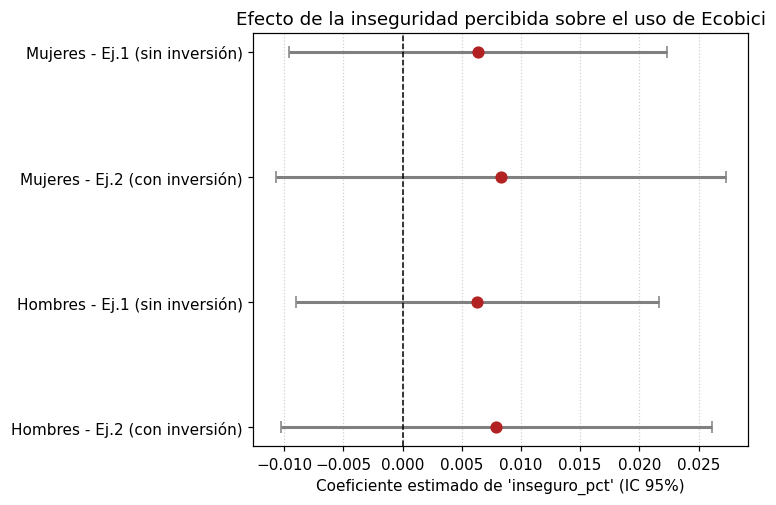

                           modelo      coef   ci_bajo   ci_alto
0  Mujeres - Ej.1 (sin inversión)  0.006377 -0.009554  0.022307
1  Mujeres - Ej.2 (con inversión)  0.008288 -0.010702  0.027278
2  Hombres - Ej.1 (sin inversión)  0.006329 -0.008996  0.021654
3  Hombres - Ej.2 (con inversión)  0.007920 -0.010299  0.026140


In [14]:
# =============================================================================
# Visualización de los resultados del panel Ecobici-Seguridad-Inversión
#
# IMPORTANTE: corre esto en una celda NUEVA, después de haber corrido
# completo el script anterior (panel_ecobici_seguridad.py) en la MISMA
# sesión de Colab. Este código reutiliza las variables que ya quedaron en
# memoria: `panel` (el DataFrame del panel completo) y `resultados`
# (diccionario con los 4 modelos ya ajustados: F_ej1, F_ej2, M_ej1, M_ej2).
#
# Incluye 3 gráficas, cada una respondiendo una pregunta distinta:
#   1) Gráfico de coeficientes (forest plot): ¿qué tan grande es el efecto
#      de la inseguridad en cada modelo, y es estadísticamente distinto
#      de cero?
#   2) Gráfico de relación parcial (Frisch-Waugh-Lovell): ¿cómo se ve la
#      relación inseguridad-viajes UNA VEZ que ya se quitó el efecto de la
#      alcaldía y del trimestre? (esto es lo que realmente estima la
#      regresión de efectos fijos, no la relación "cruda")
#   3) Tendencia descriptiva en el tiempo: viajes vs. inseguridad
#      promedio por trimestre, separado por género (contexto visual).
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS

plt.rcParams["figure.dpi"] = 110


# -----------------------------------------------------------------------
# GRÁFICO 1. Coeficientes comparados entre los 4 modelos (forest plot)
# -----------------------------------------------------------------------
# Para cada modelo, tomamos el coeficiente de 'inseguro_pct', su error
# estándar (clustered) y construimos un intervalo de confianza al 95%
# (coef ± 1.96 * error_estándar). Si el intervalo no cruza el cero, el
# efecto es estadísticamente significativo a ese nivel.

def graficar_coeficientes(resultados_dict, variable="inseguro_pct",
                           etiquetas=None, titulo=None):
    if etiquetas is None:
        etiquetas = list(resultados_dict.keys())

    filas = []
    for clave, etiqueta in zip(resultados_dict.keys(), etiquetas):
        res = resultados_dict[clave]
        if variable not in res.params.index:
            print(f"[Aviso] '{variable}' no está en el modelo '{clave}'; se omite.")
            continue
        coef = res.params[variable]
        se = res.std_errors[variable]
        filas.append({
            "modelo": etiqueta,
            "coef": coef,
            "ci_bajo": coef - 1.96 * se,
            "ci_alto": coef + 1.96 * se,
        })

    df_coef = pd.DataFrame(filas)

    fig, ax = plt.subplots(figsize=(7, 0.8 * len(df_coef) + 1.5))
    y_pos = np.arange(len(df_coef))

    ax.errorbar(
        df_coef["coef"], y_pos,
        xerr=[df_coef["coef"] - df_coef["ci_bajo"], df_coef["ci_alto"] - df_coef["coef"]],
        fmt="o", color="firebrick", ecolor="gray", elinewidth=2, capsize=4, markersize=7,
    )
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(df_coef["modelo"])
    ax.invert_yaxis()
    ax.set_xlabel(f"Coeficiente estimado de '{variable}' (IC 95%)")
    ax.set_title(titulo or f"Efecto de '{variable}' sobre log(viajes) por modelo")
    ax.grid(axis="x", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()

    return df_coef


print("\n--- Gráfico 1: coeficientes comparados (inseguro_pct) ---")
tabla_coef = graficar_coeficientes(
    resultados,
    variable="inseguro_pct",
    etiquetas=["Mujeres - Ej.1 (sin inversión)", "Mujeres - Ej.2 (con inversión)",
               "Hombres - Ej.1 (sin inversión)", "Hombres - Ej.2 (con inversión)"],
    titulo="Efecto de la inseguridad percibida sobre el uso de Ecobici",
)
print(tabla_coef)





--- Gráfico 2: relación parcial (Frisch-Waugh-Lovell), Ejercicio 1 ---


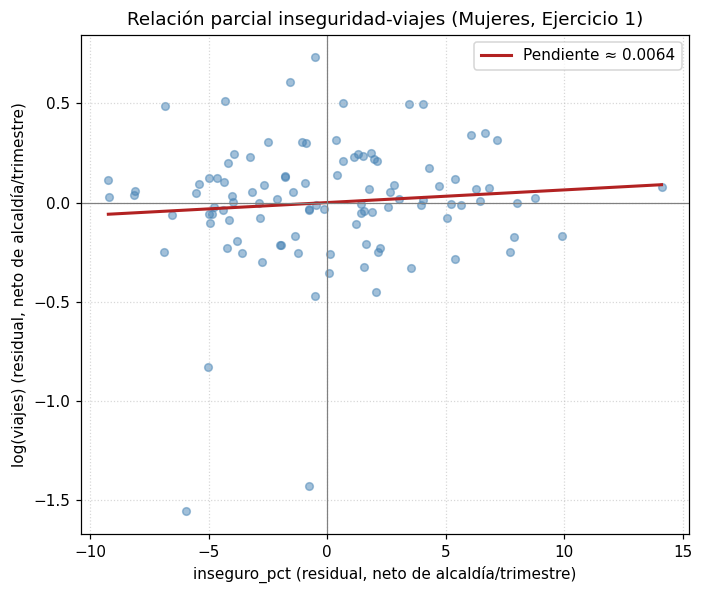

Mujeres: pendiente de la gráfica = 0.0064 (debe coincidir aprox. con el coeficiente de la tabla de resultados)


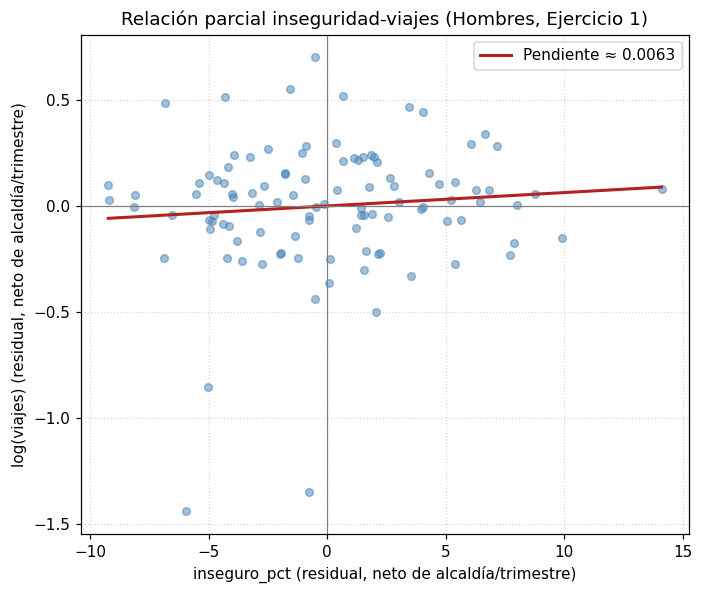

Hombres: pendiente de la gráfica = 0.0063 (debe coincidir aprox. con el coeficiente de la tabla de resultados)


In [15]:
# -----------------------------------------------------------------------
# GRÁFICO 2. Relación parcial (Frisch-Waugh-Lovell)
# -----------------------------------------------------------------------
# La regresión de Efectos Fijos NO compara directamente "alcaldías más
# inseguras vs. menos inseguras" (eso ya lo absorbe el efecto fijo de
# alcaldía). Lo que realmente identifica es: dentro de la MISMA alcaldía,
# cuando la inseguridad sube/baja de un trimestre a otro (ya neto de la
# tendencia general de la ciudad ese trimestre), ¿qué le pasa a los viajes?
#
# El teorema de Frisch-Waugh-Lovell (ver Wooldridge, cap. 3) dice que ese
# coeficiente es idéntico al que se obtiene así:
#   1) Residualizar log_viajes contra todo EXCEPTO la variable de interés
#      (pero sí incluyendo los efectos fijos y los demás controles).
#   2) Residualizar la variable de interés (inseguro_pct) de la misma forma.
#   3) Graficar esos dos residuales uno contra el otro: la pendiente de
#      esa nube de puntos es exactamente el coeficiente de la tabla.
# Esta gráfica es la forma correcta (y estándar en econometría aplicada)
# de "ver" visualmente una relación de efectos fijos.

def grafico_relacion_parcial(df_genero, variables_control, variable_interes,
                              titulo=None):
    df_idx = df_genero.copy()
    df_idx["periodo"] = df_idx["anio"].astype(int) * 4 + df_idx["trimestre"].astype(int)
    df_idx = df_idx.set_index(["alcaldia_norm", "periodo"])

    y = df_idx["log_viajes"]
    x_interes = df_idx[[variable_interes]]
    x_controles = df_idx[variables_control] if variables_control else None

    # Paso 1: residuales de log_viajes removiendo efectos fijos + controles
    #         (SIN la variable de interés)
    if variables_control:
        aux_y = PanelOLS(y, x_controles, entity_effects=True, time_effects=True,
                          drop_absorbed=True).fit()
    else:
        # si no hay controles, igual hay que remover los efectos fijos;
        # usamos una constante ficticia y nos quedamos solo con los residuales
        aux_y = PanelOLS(y, pd.DataFrame({"const": np.ones(len(y))}, index=y.index),
                          entity_effects=True, time_effects=True).fit()
    resid_y = aux_y.resids

    # Paso 2: residuales de la variable de interés, removiendo efectos
    #         fijos + los mismos controles (tratándola como si fuera "y")
    if variables_control:
        aux_x = PanelOLS(x_interes[variable_interes], x_controles,
                          entity_effects=True, time_effects=True, drop_absorbed=True).fit()
    else:
        aux_x = PanelOLS(x_interes[variable_interes],
                          pd.DataFrame({"const": np.ones(len(y))}, index=y.index),
                          entity_effects=True, time_effects=True).fit()
    resid_x = aux_x.resids

    # Alineamos ambos residuales por si algún auxiliar tiró alguna fila
    df_plot = pd.DataFrame({"resid_x": resid_x, "resid_y": resid_y}).dropna()

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ax.scatter(df_plot["resid_x"], df_plot["resid_y"], alpha=0.5, s=25, color="steelblue")

    # línea de mejor ajuste (debe tener la misma pendiente que el coef. de la tabla)
    pendiente, intercepto = np.polyfit(df_plot["resid_x"], df_plot["resid_y"], 1)
    x_linea = np.linspace(df_plot["resid_x"].min(), df_plot["resid_x"].max(), 100)
    ax.plot(x_linea, pendiente * x_linea + intercepto, color="firebrick", linewidth=2,
            label=f"Pendiente ≈ {pendiente:.4f}")

    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(f"{variable_interes} (residual, neto de alcaldía/trimestre)")
    ax.set_ylabel("log(viajes) (residual, neto de alcaldía/trimestre)")
    ax.set_title(titulo or f"Relación parcial: {variable_interes} vs. log(viajes)")
    ax.legend()
    ax.grid(linestyle=":", alpha=0.5)
    plt.tight_layout()
    plt.show()

    return df_plot, pendiente


print("\n--- Gráfico 2: relación parcial (Frisch-Waugh-Lovell), Ejercicio 1 ---")
for genero, etiqueta in [("F", "Mujeres"), ("M", "Hombres")]:
    df_g = panel[panel["genero"] == genero]
    _, pendiente = grafico_relacion_parcial(
        df_g,
        variables_control=["estaciones_activas"],
        variable_interes="inseguro_pct",
        titulo=f"Relación parcial inseguridad-viajes ({etiqueta}, Ejercicio 1)",
    )
    print(f"{etiqueta}: pendiente de la gráfica = {pendiente:.4f} "
          f"(debe coincidir aprox. con el coeficiente de la tabla de resultados)")





--- Gráfico 3: tendencia descriptiva en el tiempo ---


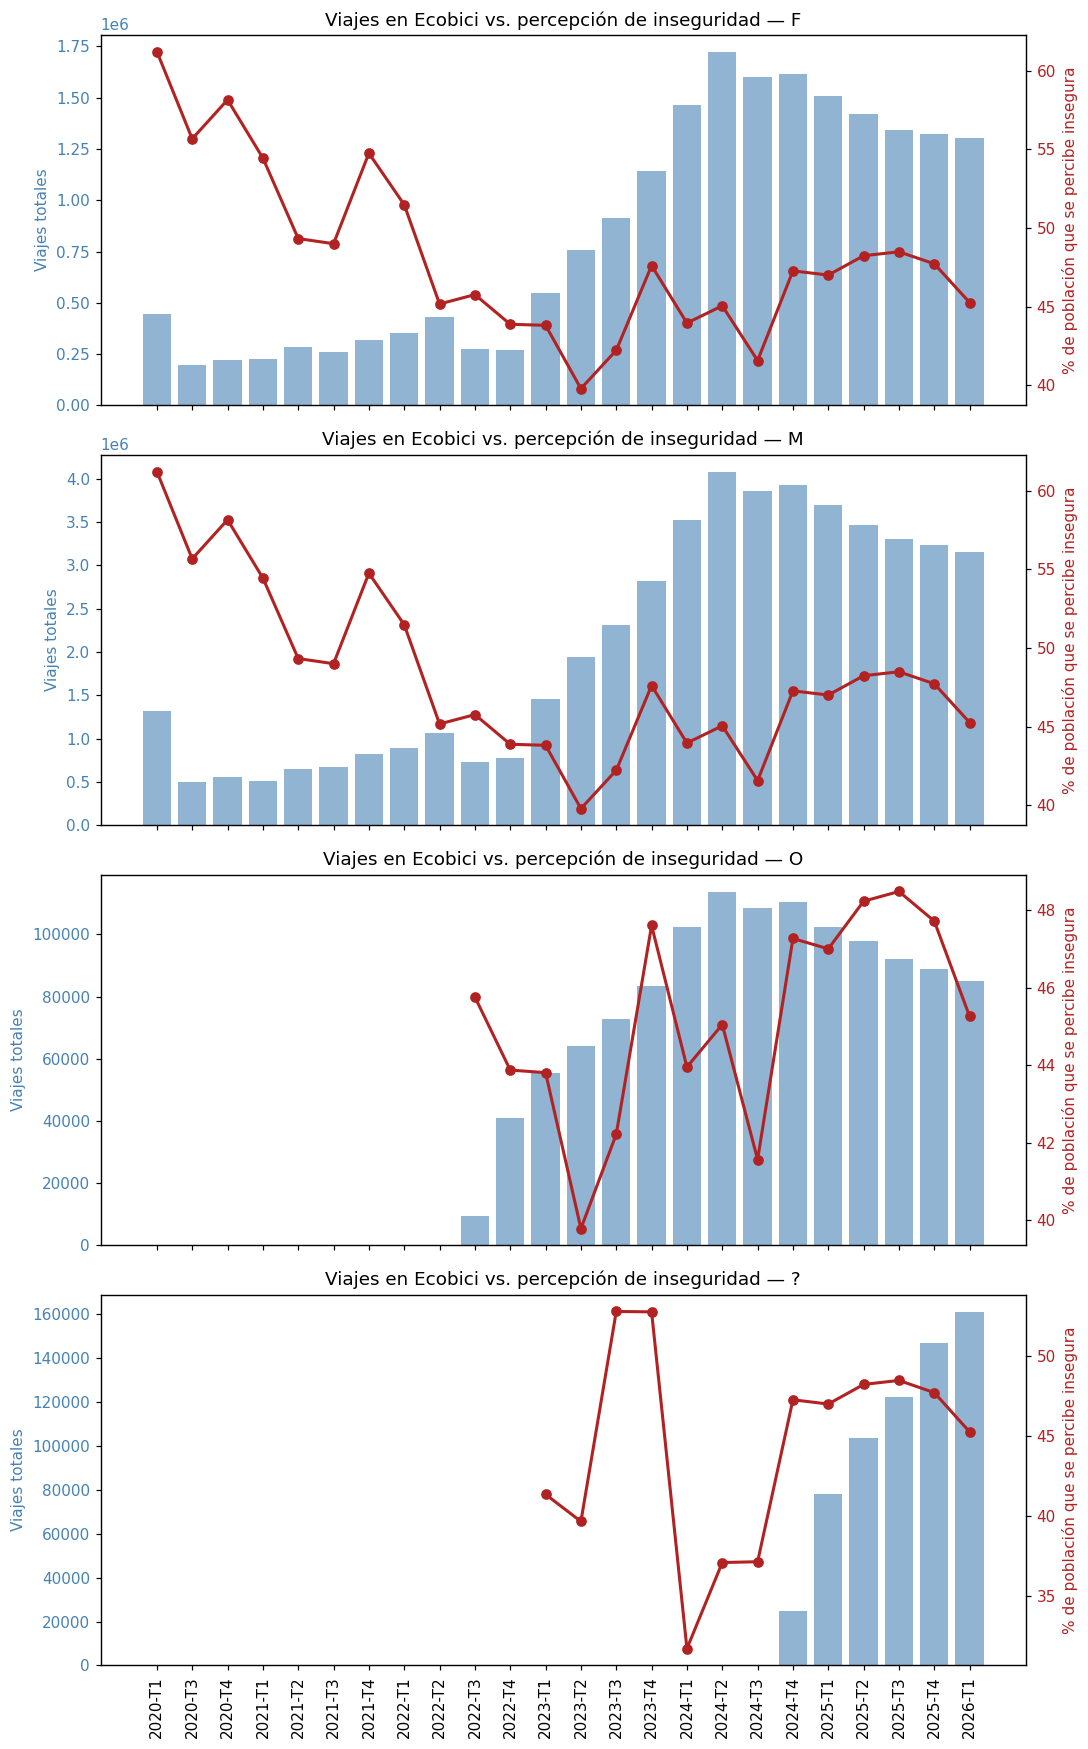

In [16]:
# -----------------------------------------------------------------------
# GRÁFICO 3. Tendencia descriptiva en el tiempo (contexto visual)
# -----------------------------------------------------------------------
# Esta gráfica NO prueba causalidad (es pura descripción, sin controlar
# por nada); sirve para dar contexto visual a los dos gráficos anteriores,
# mostrando cómo se mueven juntas la inseguridad promedio y los viajes
# promedio de la CDMX a lo largo del tiempo, por género.

def graficar_tendencia_temporal(panel_df):
    resumen = (
        panel_df
        .groupby(["anio", "trimestre", "genero"], as_index=False)
        .agg(viajes_totales=("n_viajes", "sum"),
             inseguridad_promedio=("inseguro_pct", "mean"))
        .sort_values(["anio", "trimestre"])
    )
    resumen["periodo_label"] = resumen["anio"].astype(str) + "-T" + resumen["trimestre"].astype(str)

    generos = resumen["genero"].unique()
    fig, axes = plt.subplots(len(generos), 1, figsize=(10, 4 * len(generos)), sharex=True)
    if len(generos) == 1:
        axes = [axes]

    for ax, genero in zip(axes, generos):
        sub = resumen[resumen["genero"] == genero]

        ax.bar(sub["periodo_label"], sub["viajes_totales"], color="steelblue", alpha=0.6,
               label="Viajes totales (eje izq.)")
        ax.set_ylabel("Viajes totales", color="steelblue")
        ax.tick_params(axis="y", labelcolor="steelblue")
        ax.tick_params(axis="x", rotation=90)

        ax2 = ax.twinx()
        ax2.plot(sub["periodo_label"], sub["inseguridad_promedio"], color="firebrick",
                  marker="o", linewidth=2, label="% inseguridad promedio (eje der.)")
        ax2.set_ylabel("% de población que se percibe insegura", color="firebrick")
        ax2.tick_params(axis="y", labelcolor="firebrick")

        ax.set_title(f"Viajes en Ecobici vs. percepción de inseguridad — {genero}")

    plt.tight_layout()
    plt.show()


print("\n--- Gráfico 3: tendencia descriptiva en el tiempo ---")
graficar_tendencia_temporal(panel)

Efectos agregados

In [17]:
# =============================================================================
# MODELO AGREGADO: TODOS LOS GÉNEROS
# =============================================================================
# Objetivo:
# Construir un panel alcaldía x trimestre, sumando los viajes de todos
# los géneros y manteniendo las variables que son comunes a cada
# alcaldía-trimestre.
#
# Modelo 1:
#   log(viajes) ~ inseguridad + estaciones activas
#
# Modelo 2:
#   log(viajes) ~ inseguridad + estaciones activas + log(inversión)
#
# Ambos con:
#   - efectos fijos de alcaldía
#   - efectos fijos de periodo (año-trimestre)
#   - errores estándar agrupados por alcaldía
# =============================================================================

import numpy as np
import pandas as pd
from linearmodels.panel import PanelOLS, compare


# -------------------------------------------------------------------------
# 1. Agregar viajes de todos los géneros
# -------------------------------------------------------------------------

panel_agregado = (
    panel
    .groupby(
        ["anio", "trimestre", "alcaldia_norm"],
        as_index=False
    )
    .agg(
        n_viajes=("n_viajes", "sum"),

        # Estas variables son iguales para todos los géneros dentro
        # de una misma alcaldía-trimestre, por eso usamos "first"
        inseguro_pct=("inseguro_pct", "first"),
        seguro_pct=("seguro_pct", "first"),
        estaciones_activas=("estaciones_activas", "first"),
        inversion_publica=("inversion_publica", "first")
    )
)


# -------------------------------------------------------------------------
# 2. Crear transformaciones logarítmicas
# -------------------------------------------------------------------------

panel_agregado["log_viajes"] = np.log(panel_agregado["n_viajes"] + 1)

panel_agregado["log_inversion"] = np.log(
    panel_agregado["inversion_publica"].clip(lower=1)
)


# -------------------------------------------------------------------------
# 3. Crear índice de panel alcaldía x periodo
# -------------------------------------------------------------------------

panel_agregado["periodo"] = (
    panel_agregado["anio"].astype(int) * 4
    + panel_agregado["trimestre"].astype(int)
)

panel_agregado_idx = panel_agregado.set_index(
    ["alcaldia_norm", "periodo"]
)


# -------------------------------------------------------------------------
# 4. EJERCICIO 1
#    Inseguridad + estaciones activas
# -------------------------------------------------------------------------

vars_ej1 = [
    "inseguro_pct",
    "estaciones_activas"
]

datos_ej1 = panel_agregado_idx[
    ["log_viajes"] + vars_ej1
].dropna()

modelo_agregado_ej1 = PanelOLS(
    datos_ej1["log_viajes"],
    datos_ej1[vars_ej1],
    entity_effects=True,
    time_effects=True,
    drop_absorbed=True
)

resultado_agregado_ej1 = modelo_agregado_ej1.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\n" + "="*90)
print("MODELO AGREGADO - EJERCICIO 1")
print("Inseguridad + estaciones activas")
print("="*90)

print(resultado_agregado_ej1)


# -------------------------------------------------------------------------
# 5. EJERCICIO 2
#    Inseguridad + estaciones activas + inversión pública
# -------------------------------------------------------------------------

vars_ej2 = [
    "inseguro_pct",
    "estaciones_activas",
    "log_inversion"
]

datos_ej2 = panel_agregado_idx[
    ["log_viajes"] + vars_ej2
].dropna()

modelo_agregado_ej2 = PanelOLS(
    datos_ej2["log_viajes"],
    datos_ej2[vars_ej2],
    entity_effects=True,
    time_effects=True,
    drop_absorbed=True
)

resultado_agregado_ej2 = modelo_agregado_ej2.fit(
    cov_type="clustered",
    cluster_entity=True
)

print("\n" + "="*90)
print("MODELO AGREGADO - EJERCICIO 2")
print("Inseguridad + estaciones activas + inversión pública")
print("="*90)

print(resultado_agregado_ej2)


# -------------------------------------------------------------------------
# 6. Tabla comparativa
# -------------------------------------------------------------------------

resultados_agregados = {
    "Agregado - Ej.1": resultado_agregado_ej1,
    "Agregado - Ej.2": resultado_agregado_ej2
}

print("\n" + "="*90)
print("COMPARACIÓN DE MODELOS AGREGADOS")
print("="*90)

print(compare(
    resultados_agregados,
    precision="tstats"
))


# -------------------------------------------------------------------------
# 7. Resumen rápido del coeficiente principal
# -------------------------------------------------------------------------

print("\n" + "="*90)
print("EFECTO ESTIMADO DE LA PERCEPCIÓN DE INSEGURIDAD")
print("="*90)

for nombre, res in resultados_agregados.items():

    beta = res.params["inseguro_pct"]
    se = res.std_errors["inseguro_pct"]
    t = res.tstats["inseguro_pct"]
    p = res.pvalues["inseguro_pct"]

    # Interpretación exacta en porcentaje porque Y está en log
    efecto_1pp = (np.exp(beta) - 1) * 100

    print(f"\n{nombre}")
    print(f"Coeficiente: {beta:.4f}")
    print(f"Error estándar clustered: {se:.4f}")
    print(f"t-stat: {t:.4f}")
    print(f"p-value: {p:.4f}")
    print(
        f"Interpretación: +1 punto porcentual de inseguridad "
        f"se asocia con aproximadamente {efecto_1pp:.2f}% "
        f"de cambio en los viajes totales."
    )


MODELO AGREGADO - EJERCICIO 1
Inseguridad + estaciones activas
                          PanelOLS Estimation Summary                           
Dep. Variable:             log_viajes   R-squared:                        0.0662
Estimator:                   PanelOLS   R-squared (Between):             -0.1354
No. Observations:                 105   R-squared (Within):              -0.7686
Date:                Wed, Oct 14 2026   R-squared (Overall):             -0.1807
Time:                        02:53:50   Log-likelihood                   -24.616
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      2.6223
Entities:                           6   P-value                           0.0794
Avg Obs:                       17.500   Distribution:                    F(2,74)
Min Obs:                      10.0000                                           
Max Obs:                       24.000   F-sta